**CCGT Case Study 2: Part Load Operation**

A combined cycle is most efficient at full load. When the grid needs less power the plant turns down by burning less fuel, and how it does so matters:

1. **TIT control (fixed air flow):** the compressor keeps its full air flow and the fuel flow is cut, so the turbine inlet temperature and the exhaust temperature fall. The steam cycle loses heat at both ends: less exhaust heat, at a lower temperature.
2. **Inlet guide vanes (IGV):** the compressor's variable inlet guide vanes close to reduce the air flow, which holds the exhaust temperature at its design value. The HRSG keeps producing hot steam, so the combined cycle efficiency stays higher. Below the guide vane limit (here 70 % of the design volumetric flow) the plant can only reduce the TIT.

Both strategies use the off-design model (frozen HRSG areas, turbine swallowing capacity), with the load set by the fuel flow.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from ccgt import setup_ccgt_model, set_mode, ccgt_results
from ccgt_case_studies import solve

pd.set_option("display.max_columns", 40)

# Design point (DWSIM specifications), then the design targets (TIT 1350 C, 10 K pinch)
model, results = setup_ccgt_model()
set_mode(model, "targets")
solve(model)
# Off-design: HRSG areas frozen at their design values, compressor volumetric flow and turbine swallowing capacity fixed
set_mode(model, "offdesign")
solve(model)
design = ccgt_results(model)
print("Net power {0:.0f} kW, efficiency {1:.2f} %".format(design["Plant net power (kW)"],
                                                          design["Combined cycle efficiency LHV (%)"]))

2026-11-12 16:51:45 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:51:45 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:51:45 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:51:45 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_in[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:51:45 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_out[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:51:45 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.properties_isentropic[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


... (43 outputs left out)

2026-11-12 16:51:45 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.economizer.cold_side.heat


2026-11-12 16:51:45 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.condenser.control_volume.heat


The DOF is 0


Net power 27113 kW, efficiency 56.08 %


## Part load sweeps

In [3]:
from ccgt_case_studies import part_load_tit, part_load_igv

tit = part_load_tit(model)
igv = part_load_igv(model, min_air=0.70)
cols = ["Load (%)", "Plant net power (kW)", "Combined cycle efficiency LHV (%)", "Heat rate LHV (kJ/kWh)",
        "Turbine inlet temperature (C)", "GT exhaust temperature (C)", "Pressure ratio", "Steam flow (kg/s)",
        "Steam temperature (C)", "Stack temperature (C)"]
print("TIT control")
display(tit[cols].round(2))
print("Inlet guide vanes")
igv[cols + ["Air flow fraction"]].round(2)

TIT control


,Load (%),Plant net power (kW),Combined cycle efficiency LHV (%),Heat rate LHV (kJ/kWh),Turbine inlet temperature (C),GT exhaust temperature (C),Pressure ratio,Steam flow (kg/s),Steam temperature (C),Stack temperature (C)
Fuel flow fraction,,,,,,,,,,
1.0,100.00,27113.25,56.08,6419.61,1350.00,666.92,17.00,7.93,500.00,104.99
0.9,88.20,23915.12,54.96,6550.28,1263.67,615.84,16.49,7.08,483.26,113.77
0.8,76.69,20792.31,53.76,6696.95,1174.79,563.41,15.96,6.32,461.47,117.22
0.7,65.17,17669.19,52.21,6895.59,1083.25,509.53,15.40,5.53,435.88,121.35
0.6,53.65,14545.21,50.14,7179.95,988.49,454.10,14.81,4.72,405.70,126.52
0.5,42.11,11416.80,47.23,7622.82,890.23,396.98,14.19,3.87,369.97,133.47
0.4,30.48,8263.31,42.73,8425.51,787.96,338.01,13.52,2.93,327.53,144.48


Inlet guide vanes


,Load (%),Plant net power (kW),Combined cycle efficiency LHV (%),Heat rate LHV (kJ/kWh),Turbine inlet temperature (C),GT exhaust temperature (C),Pressure ratio,Steam flow (kg/s),Steam temperature (C),Stack temperature (C),Air flow fraction
Fuel flow fraction,,,,,,,,,,,
1.0,100.00,27113.31,56.08,6419.59,1350.00,666.92,17.00,7.93,500.00,104.99,1.00
0.9,89.26,24201.36,55.62,6472.81,1321.96,666.92,15.45,7.22,512.98,101.05,0.91
0.8,78.55,21297.91,55.06,6537.97,1291.01,666.92,13.90,6.50,527.54,97.40,0.83
0.7,67.88,18405.75,54.38,6619.64,1256.40,666.92,12.34,5.77,543.89,94.11,0.74
0.6,56.31,15268.83,52.63,6839.67,1170.65,624.26,11.33,4.86,535.10,112.25,0.70
0.5,45.06,12217.58,50.54,7123.19,1040.32,543.16,10.77,4.10,487.75,117.96,0.70
0.4,33.91,9195.39,47.55,7571.46,903.45,458.48,10.16,3.30,429.97,123.99,0.70


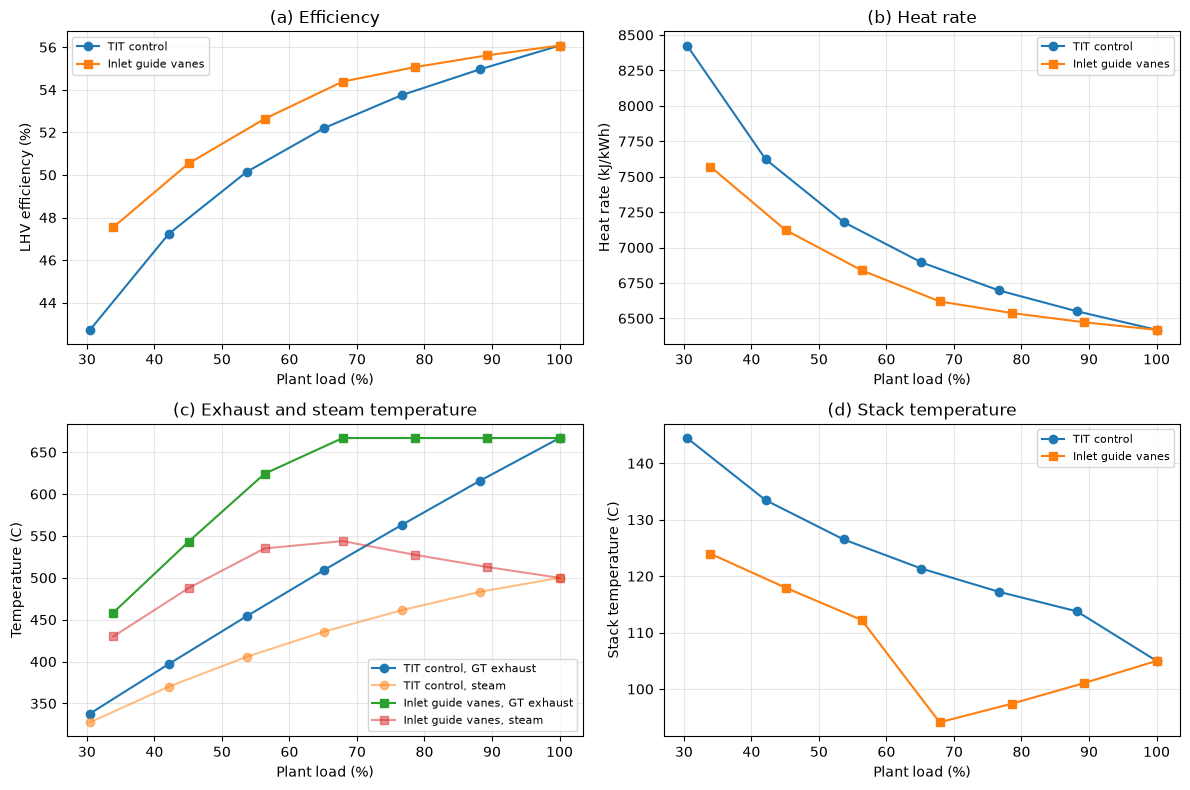

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
cases = ((tit, "o-", "TIT control"), (igv, "s-", "Inlet guide vanes"))
for df, style, label in cases:
    axes[0, 0].plot(df["Load (%)"], df["Combined cycle efficiency LHV (%)"], style, label=label)
    axes[0, 1].plot(df["Load (%)"], df["Heat rate LHV (kJ/kWh)"], style, label=label)
    axes[1, 0].plot(df["Load (%)"], df["GT exhaust temperature (C)"], style, label=label + ", GT exhaust")
    axes[1, 0].plot(df["Load (%)"], df["Steam temperature (C)"], style, alpha=0.5, label=label + ", steam")
    axes[1, 1].plot(df["Load (%)"], df["Stack temperature (C)"], style, label=label)
axes[0, 0].set_ylabel("LHV efficiency (%)")
axes[0, 0].set_title("(a) Efficiency")
axes[0, 1].set_ylabel("Heat rate (kJ/kWh)")
axes[0, 1].set_title("(b) Heat rate")
axes[1, 0].set_ylabel("Temperature (C)")
axes[1, 0].set_title("(c) Exhaust and steam temperature")
axes[1, 1].set_ylabel("Stack temperature (C)")
axes[1, 1].set_title("(d) Stack temperature")
for ax in axes.flat:
    ax.set_xlabel("Plant load (%)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What the curves show**

* With **TIT control** the efficiency falls steadily, from 56 % at full load to about 50 % at 54 % load and 43 % at 30 % load. The colder exhaust raises less steam at a lower temperature, and the stack temperature rises.
* With **inlet guide vanes** the exhaust stays at its design temperature down to about 68 % load, and the efficiency only drops to about 54 %. Below the guide vane limit the plant falls back to TIT control, but from a better starting point, so at the same load it stays 2–4 points more efficient.
* **Superheated steam temperature:** with the guide vanes closing, the same exhaust temperature meets a smaller gas flow, and the fixed area superheater overheats the steam (up to ~545 °C here). Real HRSGs use an attemperator (spray water) to cap it; this simplified model does not.

### HRSG at 70 % fuel: T–Q diagrams of the two strategies

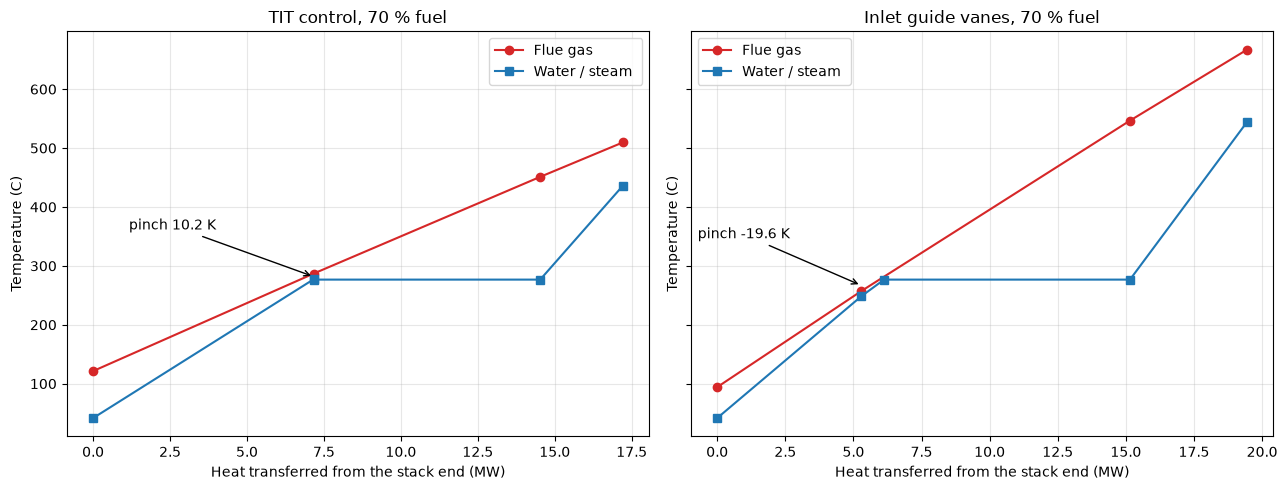

Back at 27113 kW


In [5]:
from ccgt import plot_tq
from ccgt_case_studies import step_to, set_fuel_control, restore_tit_control, _fuel_flow
from pyomo.environ import value

t = model.fs.time.first()
f0 = value(_fuel_flow(model))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# TIT control at 70 % fuel
set_fuel_control(model)
step_to(model, lambda m, x: _fuel_flow(m).fix(x * f0), 1.0, 0.7)
plot_tq(axes[0], model)
axes[0].set_title("TIT control, 70 % fuel")

# Inlet guide vanes at 70 % fuel: hold the design exhaust temperature
step_to(model, lambda m, x: _fuel_flow(m).fix(x * f0), 0.7, 1.0)
exhaust_T = model.fs.gas_turbine.control_volume.properties_out[t].temperature
model.fs.air_volumetric_flow.unfix()
exhaust_T.fix()
step_to(model, lambda m, x: _fuel_flow(m).fix(x * f0), 1.0, 0.7)
plot_tq(axes[1], model)
axes[1].set_title("Inlet guide vanes, 70 % fuel")
plt.tight_layout()
plt.show()

# Back to the full load design point
step_to(model, lambda m, x: _fuel_flow(m).fix(x * f0), 0.7, 1.0)
exhaust_T.unfix()
model.fs.air_volumetric_flow.fix()
restore_tit_control(model)
print("Back at {0:.0f} kW".format(ccgt_results(model)["Plant net power (kW)"]))